# CSCI461 – Assignment #1
**Dataset:** YouTube Spam Collection

**Team:**
1. Zeyad Ahmed
2. Mohamed Abdellatif
3. Steven Wilson
4. Abdalsalam Zaqzouq



In [1]:
import re, html, unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer, MinMaxScaler
from sklearn.cluster import KMeans

from nltk.tokenize import RegexpTokenizer

In [2]:
#for recreation
SEED = 42
np.random.seed(SEED)

ROOT = Path("..") if Path("../data/dataset.csv").exists() else Path(".")
DATA_PATH = ROOT / "data" / "dataset.csv"
OUT_DIR = ROOT / "output"
FIG_DIR = OUT_DIR / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Data file    :", DATA_PATH.resolve())
print("Output folder:", OUT_DIR.resolve())

Data file    : /home/jovyan/work/data/dataset.csv
Output folder: /home/jovyan/work/output


# Dataset understanding:

In [3]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

display(df.head())
print("Shape  :", df.shape)
print("Columns:", list(df.columns))

,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy


Shape  : (1956, 6)
Columns: ['COMMENT_ID', 'AUTHOR', 'DATE', 'CONTENT', 'CLASS', 'VIDEO']


In [4]:
display(df.dtypes.to_frame("dtype"))
df.info()

,dtype
COMMENT_ID,str
AUTHOR,str
DATE,str
CONTENT,str
CLASS,int64
VIDEO,str


<class 'pandas.DataFrame'>
RangeIndex: 1956 entries, 0 to 1955
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   COMMENT_ID  1956 non-null   str  
 1   AUTHOR      1956 non-null   str  
 2   DATE        1711 non-null   str  
 3   CONTENT     1956 non-null   str  
 4   CLASS       1956 non-null   int64
 5   VIDEO       1956 non-null   str  
dtypes: int64(1), str(5)
memory usage: 424.6 KB


In [5]:
print("\nRecords per video:")
display(df["VIDEO"].value_counts().to_frame("comments"))
print("\nClass balance (1 = Spam, 0 = Not Spam):")
display(df["CLASS"].value_counts().to_frame("comments"))


Records per video:


,comments
VIDEO,
Eminem,448
LMFAO,438
Shakira,370
Psy,350
KatyPerry,350



Class balance (1 = Spam, 0 = Not Spam):


,comments
CLASS,
1,1005
0,951


**What does one row represent?** One row is **one YouTube comment** posted under one of five music videos, with its author, timestamp, text, a spam label and the video it came from.

| Column | Meaning | Type of variable |
|---|---|---|
| `COMMENT_ID` | unique id of the comment | identifier (not used for modelling) |
| `AUTHOR` | commenter's display name | text (not analysed here) |
| `DATE` | time of the comment | date/time (stored as text at first) |
| `CONTENT` | the comment itself | **text** (main analysis column) |
| `CLASS` | 1 = Spam, 0 = Not Spam | **label / category** (target) |
| `VIDEO` | which video the comment belongs to (added by `prepare_dataset.py` from the file name) | **category** (natural clusters) |

There are no numerical columns in the raw data (`CLASS` is a 0/1 label). The numerical columns are created later from the text.

# Missing values and duplicates:

In [6]:
print("Shape before cleaning:", df.shape)
missing = df.isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(df) * 100).round(2)
display(missing)

print("Fully duplicated rows            :", df.duplicated().sum())
print("Rows whose CONTENT is a repeat   :", df.duplicated(subset="CONTENT").sum())

Shape before cleaning: (1956, 6)


,missing,percent
COMMENT_ID,0,0.00
AUTHOR,0,0.00
DATE,245,12.53
CONTENT,0,0.00
CLASS,0,0.00
VIDEO,0,0.00


Fully duplicated rows            : 3
Rows whose CONTENT is a repeat   : 196


In [7]:
# Remove comment with no text.
df = df.dropna(subset=["CONTENT"])
df["CONTENT"] = df["CONTENT"].astype(str).str.strip()
df = df[df["CONTENT"] != ""]

# Keep the first occurrence of exact duplicate comment texts
df = df.drop_duplicates(subset="CONTENT", keep="first")

df = df.reset_index(drop=True)

print("Shape before cleaning:", df_raw.shape)
print("Shape after cleaning :", df.shape)
print("Rows removed         :", len(df_raw) - len(df))
print("Missing values left  :\n", df.isna().sum().to_string())

Shape before cleaning: (1956, 6)
Shape after cleaning : (1759, 6)
Rows removed         : 197
Missing values left  :
 COMMENT_ID      0
AUTHOR          0
DATE          207
CONTENT         0
CLASS           0
VIDEO           0


Date is not important (will not be used by the models)

# loc / iloc:

In [8]:
# Spam comments from Psy video
spam_psy = df.loc[(df["CLASS"] == 1) & (df["VIDEO"] == "Psy"), ["AUTHOR", "CONTENT", "CLASS"]]
print("Spam comments on the Psy video:", len(spam_psy))
display(spam_psy.head())

# iloc with np.r_: rows 0-4, and the last 3 rows
display(df.iloc[np.r_[:5, -3:0]])

Spam comments on the Psy video: 175


,AUTHOR,CONTENT,CLASS
0,Julius NM,"Huh, anyway check out this you[tube] channel: ...",1
1,adam riyati,Hey guys check out my new channel and our firs...,1
2,Evgeny Murashkin,just for test I have to say murdev.com,1
3,ElNino Melendez,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1
4,GsMega,watch?v=vtaRGgvGtWQ Check this out .﻿,1


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07T06:20:48,"Huh, anyway check out this you[tube] channel: ...",1,Psy
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07T12:37:15,Hey guys check out my new channel and our firs...,1,Psy
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08T17:34:21,just for test I have to say murdev.com,1,Psy
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09T08:28:43,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10T16:05:38,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy
1756,_2viQ_Qnc6-pY-1yR6K2FhmC5i48-WuNx5CumlHLDAI,Sabina Pearson-Smith,2013-07-13T13:14:30.021000,I love this song for two reasons: 1.it is abou...,0,Shakira
1757,_2viQ_Qnc6_yBt8UGMWyg3vh0PulTqcqyQtdE7d4Fl0,Aishlin Maciel,2013-07-13T11:17:52.308000,Shakira u are so wiredo,0,Shakira
1758,_2viQ_Qnc685RPw1aSa1tfrIuHXRvAQ2rPT9R06KTqA,Latin Bosch,2013-07-12T22:33:27.916000,Shakira is the best dancer,0,Shakira


# Transformation & Feature Creation:

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1759 entries, 0 to 1758
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   COMMENT_ID  1759 non-null   str  
 1   AUTHOR      1759 non-null   str  
 2   DATE        1552 non-null   str  
 3   CONTENT     1759 non-null   str  
 4   CLASS       1759 non-null   int64
 5   VIDEO       1759 non-null   str  
dtypes: int64(1), str(5)
memory usage: 385.3 KB


In [10]:
# Type conversion: DATE text -> datetime, VIDEO -> category
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce", format="mixed", utc=True)
df["VIDEO"] = df["VIDEO"].astype("category")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1759 entries, 0 to 1758
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype              
---  ------      --------------  -----              
 0   COMMENT_ID  1759 non-null   str                
 1   AUTHOR      1759 non-null   str                
 2   DATE        1552 non-null   datetime64[us, UTC]
 3   CONTENT     1759 non-null   str                
 4   CLASS       1759 non-null   int64              
 5   VIDEO       1759 non-null   category           
dtypes: category(1), datetime64[us, UTC](1), int64(1), str(3)
memory usage: 328.0 KB


In [11]:
# Encoding: readable label + integer code for the video
df["LABEL"] = df["CLASS"].map({0: "Not Spam", 1: "Spam"})
df["VIDEO_CODE"] = df["VIDEO"].cat.codes

In [12]:
# Feature creation: length of the comment (char)
df["char_count"] = df["CONTENT"].str.len()

In [13]:
# Binning: group comments by length (including 0)
df["length_bin"] = pd.cut(df["char_count"],
                          bins=[0, 30, 80, 200, np.inf], labels=["very short (<=30)", "short (31-80)", "medium (81-200)", "long (>200)"],
                          include_lowest=True)

In [14]:
# T5 - Normalization: min-max scale char_count to the range 0-1
df["char_count_scaled"] = MinMaxScaler().fit_transform(df[["char_count"]]).ravel()

In [15]:
df.info()
df.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 1759 entries, 0 to 1758
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   COMMENT_ID         1759 non-null   str                
 1   AUTHOR             1759 non-null   str                
 2   DATE               1552 non-null   datetime64[us, UTC]
 3   CONTENT            1759 non-null   str                
 4   CLASS              1759 non-null   int64              
 5   VIDEO              1759 non-null   category           
 6   LABEL              1759 non-null   str                
 7   VIDEO_CODE         1759 non-null   int8               
 8   char_count         1759 non-null   int64              
 9   length_bin         1759 non-null   category           
 10  char_count_scaled  1759 non-null   float64            
dtypes: category(2), datetime64[us, UTC](1), float64(1), int64(2), int8(1), str(4)
memory usage: 383.4 KB


,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO,LABEL,VIDEO_CODE,char_count,length_bin,char_count_scaled
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07 06:20:48+00:00,"Huh, anyway check out this you[tube] channel: ...",1,Psy,Spam,3,56,short (31-80),0.045075
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07 12:37:15+00:00,Hey guys check out my new channel and our firs...,1,Psy,Spam,3,166,medium (81-200),0.136895
2,LZQPQhLyRh9MSZYnf8djyk0gEF9BHDPYrrK-qCczIY8,Evgeny Murashkin,2013-11-08 17:34:21+00:00,just for test I have to say murdev.com,1,Psy,Spam,3,38,short (31-80),0.030050
3,z13jhp0bxqncu512g22wvzkasxmvvzjaz04,ElNino Melendez,2013-11-09 08:28:43+00:00,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,Psy,Spam,3,48,short (31-80),0.038397
4,z13fwbwp1oujthgqj04chlngpvzmtt3r3dw,GsMega,2013-11-10 16:05:38+00:00,watch?v=vtaRGgvGtWQ Check this out .﻿,1,Psy,Spam,3,39,short (31-80),0.030885


# Sampling:

In [16]:
frac = 0.20

# Simple random sampling
simple = df.sample(frac=frac, random_state=SEED)

# Stratified sampling: sample 20 from each class
strat = df.groupby("CLASS", group_keys=False).sample(frac=frac, random_state=SEED)

# Cluster sampling: randomly choose whole videos (clusters) and keep ALL their comments
rng = np.random.default_rng(SEED)
all_videos = list(df["VIDEO"].cat.categories)
chosen = list(rng.choice(all_videos, size=2, replace=False))
cluster = df[df["VIDEO"].isin(chosen)]

print("Clusters (videos) chosen:", chosen)
print({"original": len(df), "simple random": len(simple), "stratified": len(strat), "cluster": len(cluster)})

Clusters (videos) chosen: [np.str_('Eminem'), np.str_('Psy')]
{'original': 1759, 'simple random': 352, 'stratified': 352, 'cluster': 754}


Label distribution (%):


,Original,Simple random,Stratified,Cluster
LABEL,,,,
Not Spam,52.2,50.9,52.3,49.3
Spam,47.8,49.1,47.7,50.7


Video distribution (%):


,Original,Simple random,Stratified,Cluster
VIDEO,,,,
Eminem,23.0,21.0,24.4,53.7
KatyPerry,19.7,22.4,21.3,0.0
LMFAO,19.3,19.3,19.3,0.0
Psy,19.8,19.0,17.9,46.3
Shakira,18.1,18.2,17.0,0.0


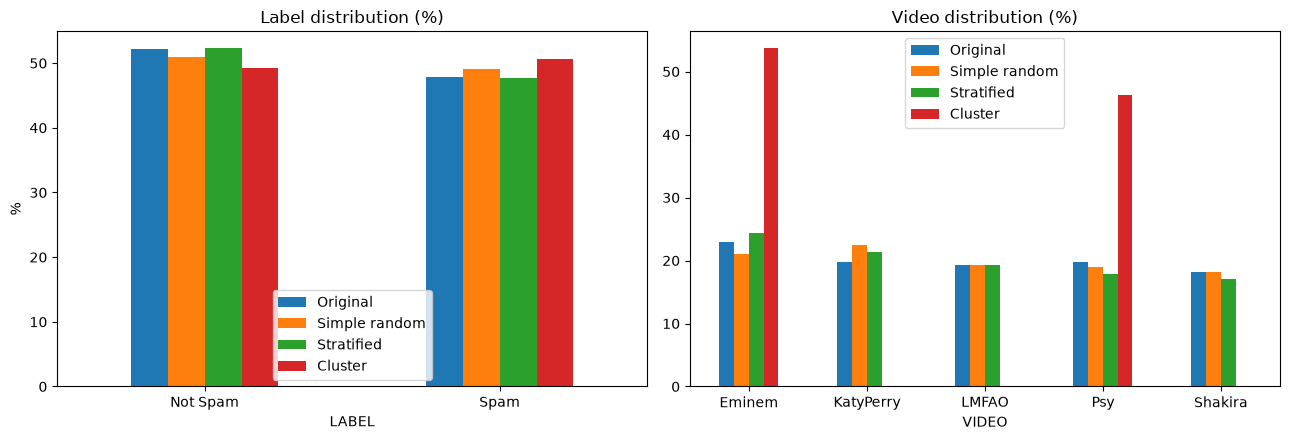

In [17]:
def dist(frame, col, order):
    return (frame[col].astype(str).value_counts(normalize=True).reindex(order).fillna(0) * 100).round(1)

label_order = ["Not Spam", "Spam"]
label_cmp = pd.DataFrame({"Original": dist(df, "LABEL", label_order),
                          "Simple random": dist(simple, "LABEL", label_order),
                          "Stratified": dist(strat, "LABEL", label_order),
                          "Cluster": dist(cluster, "LABEL", label_order)})
video_cmp = pd.DataFrame({"Original": dist(df, "VIDEO", all_videos),
                          "Simple random": dist(simple, "VIDEO", all_videos),
                          "Stratified": dist(strat, "VIDEO", all_videos),
                          "Cluster": dist(cluster, "VIDEO", all_videos)})
print("Label distribution (%):");  display(label_cmp)
print("Video distribution (%):");  display(video_cmp)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
label_cmp.plot(kind="bar", ax=axes[0], rot=0); axes[0].set_title("Label distribution (%)"); axes[0].set_ylabel("%")
video_cmp.plot(kind="bar", ax=axes[1], rot=0);  axes[1].set_title("Video distribution (%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "sampling_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

1. The distribution betwen **Spam** and **Not Spam** in all the of the sampling techniques is almost 50/50, this is due to the original data already being nearly balanced.
2. In the Cluster sampling, Eminem is more that Psy simply because eminem has more total videos that Psy (448 / 350)

# Correlation:

In [18]:
words = df["CONTENT"].str.split()
lower_words = df["CONTENT"].str.lower().str.split()

df["word_count"] = words.str.len()
df["unique_word_count"] = lower_words.apply(lambda w: len(set(w)))
df["avg_word_length"] = words.apply(lambda w: np.mean([len(x) for x in w]) if len(w) else 0)
df["digit_count"] = df["CONTENT"].str.count(r"\d")
df["exclamation_count"] = df["CONTENT"].str.count("!")
df["uppercase_ratio"] = df["CONTENT"].str.count(r"[A-Z]") / df["char_count"]
df["url_count"] = df["CONTENT"].str.count(r"(?i)https?://|www\.")

num_features = ["char_count", "word_count", "unique_word_count", "avg_word_length",
                "digit_count", "exclamation_count", "uppercase_ratio", "url_count"]
display(df[num_features].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
char_count,1759.0,96.08,126.58,2.00,28.00,52.00,103.00,1200.0
word_count,1759.0,15.64,20.93,1.00,4.00,8.00,16.00,213.0
unique_word_count,1759.0,13.43,15.61,1.00,4.00,8.00,15.00,128.0
avg_word_length,1759.0,7.80,23.67,1.42,4.00,4.56,5.55,705.0
digit_count,1759.0,2.78,13.81,0.00,0.00,0.00,2.00,354.0
exclamation_count,1759.0,1.44,17.64,0.00,0.00,0.00,1.00,695.0
uppercase_ratio,1759.0,0.10,0.17,0.00,0.01,0.04,0.09,1.0
url_count,1759.0,0.21,0.84,0.00,0.00,0.00,0.00,20.0


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1759 entries, 0 to 1758
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   COMMENT_ID         1759 non-null   str                
 1   AUTHOR             1759 non-null   str                
 2   DATE               1552 non-null   datetime64[us, UTC]
 3   CONTENT            1759 non-null   str                
 4   CLASS              1759 non-null   int64              
 5   VIDEO              1759 non-null   category           
 6   LABEL              1759 non-null   str                
 7   VIDEO_CODE         1759 non-null   int8               
 8   char_count         1759 non-null   int64              
 9   length_bin         1759 non-null   category           
 10  char_count_scaled  1759 non-null   float64            
 11  word_count         1759 non-null   int64              
 12  unique_word_count  1759 non-null   int64              
 13 

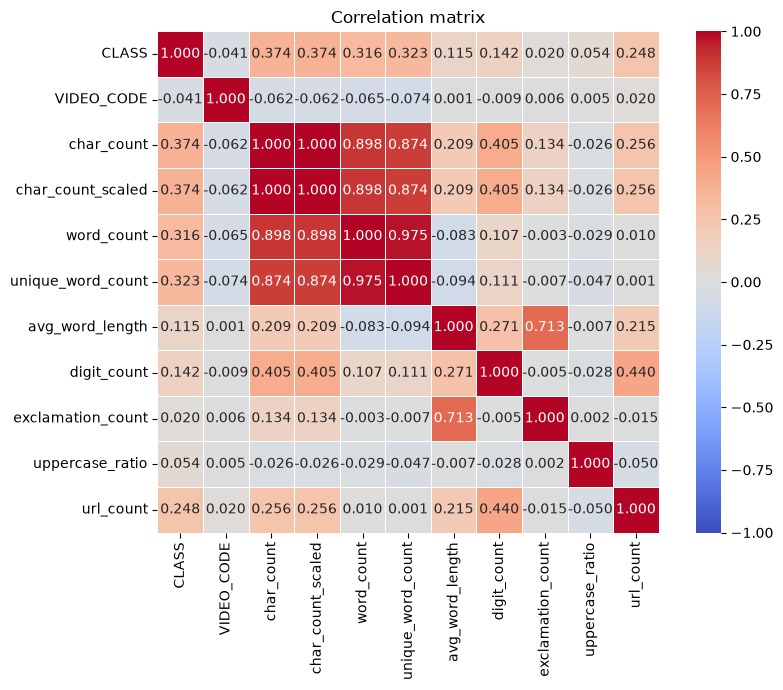

Correlation of each feature with CLASS:


,Corr with CLASS
char_count_scaled,0.374
char_count,0.374
unique_word_count,0.323
word_count,0.316
url_count,0.248
digit_count,0.142
avg_word_length,0.115
uppercase_ratio,0.054
exclamation_count,0.020
VIDEO_CODE,-0.041


Strongest feature pairs:


Correlation
char_count        char_count_scaled        1.000
word_count        unique_word_count        0.975
char_count        word_count               0.898
char_count_scaled word_count               0.898
                  unique_word_count        0.874
char_count        unique_word_count        0.874
avg_word_length   exclamation_count        0.713
digit_count       url_count                0.440
char_count_scaled digit_count              0.405
char_count        digit_count              0.405

In [20]:
corr = df.drop(columns=["COMMENT_ID", "AUTHOR", "DATE", "CONTENT", "VIDEO", "LABEL", "length_bin"]).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlation of each feature with CLASS:")
display(corr["CLASS"].drop("CLASS").sort_values(ascending=False).round(3).to_frame("Corr with CLASS"))

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print("Strongest feature pairs:")
display(pairs.head(10).round(3).to_frame("Correlation"))

**Correlation does not imply causation:** 

A correlation only means that two variables move together. For example, if spam comments are longer, that does not mean that length makes a comment spam. It means that spammers simply tend to paste long promotional text.

# Text cleaning:

In [21]:
URL_RE = re.compile(r"(?:https?://|www\.)\S+|\b[\w-]+\.(?:com|net|org|ly|me|tv|co)\b\S*", re.I)

def clean_text(text):
    if pd.isna(text):
        return ""                                         # handle missing text
    t = html.unescape(str(text))                          # &amp; &#39; -> & '
    t = re.sub(r"<[^>]+>", " ", t)                        # <br />, <a href=...>
    t = t.lower()
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()   # strip accents / emojis
    t = URL_RE.sub(" url ", t)                            # URLs -> token "url"
    t = re.sub(r"['\u2019]", "", t)                       # don't -> dont
    t = re.sub(r"\d+", " num ", t)                        # numbers -> switch to "num" | Presence of numbers > the number itself
    t = re.sub(r"[^a-z\s]", " ", t)                       # remove punctuation / symbols
    t = re.sub(r"\s+", " ", t).strip()                    # collapse spaces
    return t

df["cleaned_text"] = df["CONTENT"].apply(clean_text)

display(df[["CONTENT", "cleaned_text"]].sample(8, random_state=SEED))

n_empty = int((df["cleaned_text"] == "").sum())
print("Comments that became empty after cleaning (e.g. emoji-only):", n_empty)
df = df[df["cleaned_text"] != ""].reset_index(drop=True)
print("Dataset size after removing empty cleaned_text:", df.shape)

,CONTENT,cleaned_text
1125,EVERYONE GO AND SHARE youtu be/ARkglzjQuP0 ON...,everyone go and share youtu be arkglzjqup num ...
1030,EVERYONE PLEASE GO SUBSCRIBE TO MY CHANNEL OR ...,everyone please go subscribe to my channel or ...
1450,I don&#39;t think this song will ever get old ﻿,i dont think this song will ever get old
1494,I love you﻿,i love you
344,How can this have 2 billion views when there's...,how can this have num billion views when there...
1022,check it out free stuff for watching videos an...,check it out free stuff for watching videos an...
1549,wow,wow
322,Limit sun exposure while driving. Eliminate th...,limit sun exposure while driving eliminate the...


Comments that became empty after cleaning (e.g. emoji-only): 6
Dataset size after removing empty cleaned_text: (1753, 19)


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1753 entries, 0 to 1752
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   COMMENT_ID         1753 non-null   str                
 1   AUTHOR             1753 non-null   str                
 2   DATE               1546 non-null   datetime64[us, UTC]
 3   CONTENT            1753 non-null   str                
 4   CLASS              1753 non-null   int64              
 5   VIDEO              1753 non-null   category           
 6   LABEL              1753 non-null   str                
 7   VIDEO_CODE         1753 non-null   int8               
 8   char_count         1753 non-null   int64              
 9   length_bin         1753 non-null   category           
 10  char_count_scaled  1753 non-null   float64            
 11  word_count         1753 non-null   int64              
 12  unique_word_count  1753 non-null   int64              
 13 

# Tokenization:

In [23]:
tokenizer = RegexpTokenizer(r"[a-z]+")
df["tokens"] = df["cleaned_text"].apply(tokenizer.tokenize)
df["token_count"] = df["tokens"].str.len()

all_tokens = [t for toks in df["tokens"] for t in toks]
stats = {"Total tokens": len(all_tokens),
         "Unique words (vocabulary)": len(set(all_tokens)),
         "Average words per record": round(df["token_count"].mean(), 2),
         "Median words per record": float(df["token_count"].median())}
display(pd.Series(stats, name="value").to_frame())

,value
Total tokens,27144.00
Unique words (vocabulary),3632.00
Average words per record,15.48
Median words per record,8.00


In [24]:
df.head(2)

,COMMENT_ID,AUTHOR,DATE,CONTENT,CLASS,VIDEO,LABEL,VIDEO_CODE,char_count,length_bin,...,word_count,unique_word_count,avg_word_length,digit_count,exclamation_count,uppercase_ratio,url_count,cleaned_text,tokens,token_count
0,LZQPQhLyRh80UYxNuaDWhIGQYNQ96IuCg-AYWqNPjpU,Julius NM,2013-11-07 06:20:48+00:00,"Huh, anyway check out this you[tube] channel: ...",1,Psy,Spam,3,56,short (31-80),...,8,8,6.125,2,0,0.017857,0,huh anyway check out this you tube channel kob...,"[huh, anyway, check, out, this, you, tube, cha...",10
1,LZQPQhLyRh_C2cTtd9MvFRJedxydaVW-2sNg5Diuo4A,adam riyati,2013-11-07 12:37:15+00:00,Hey guys check out my new channel and our firs...,1,Psy,Spam,3,166,medium (81-200),...,30,27,4.500,0,7,0.120482,0,hey guys check out my new channel and our firs...,"[hey, guys, check, out, my, new, channel, and,...",31


# Most frequent words:

WITH stop words       WITHOUT stop words      
              word count               word count
1              num   863                num   863
2                i   711              check   394
3              the   679                url   319
4              and   591               song   280
5             this   589               like   236
6               to   576          subscribe   217
7              you   534              video   204
8               my   502               love   189
9                a   443            channel   187
10             out   404                 im   153
11           check   394               just   150
12              it   333              music   128
13              is   327            youtube   119
14             url   319               guys   117
15            song   280              views   107
16              of   264               dont    88
17              on   248                new    82
18             for   247               best    79
19            like   236                hey    78
20          please   234              money    77

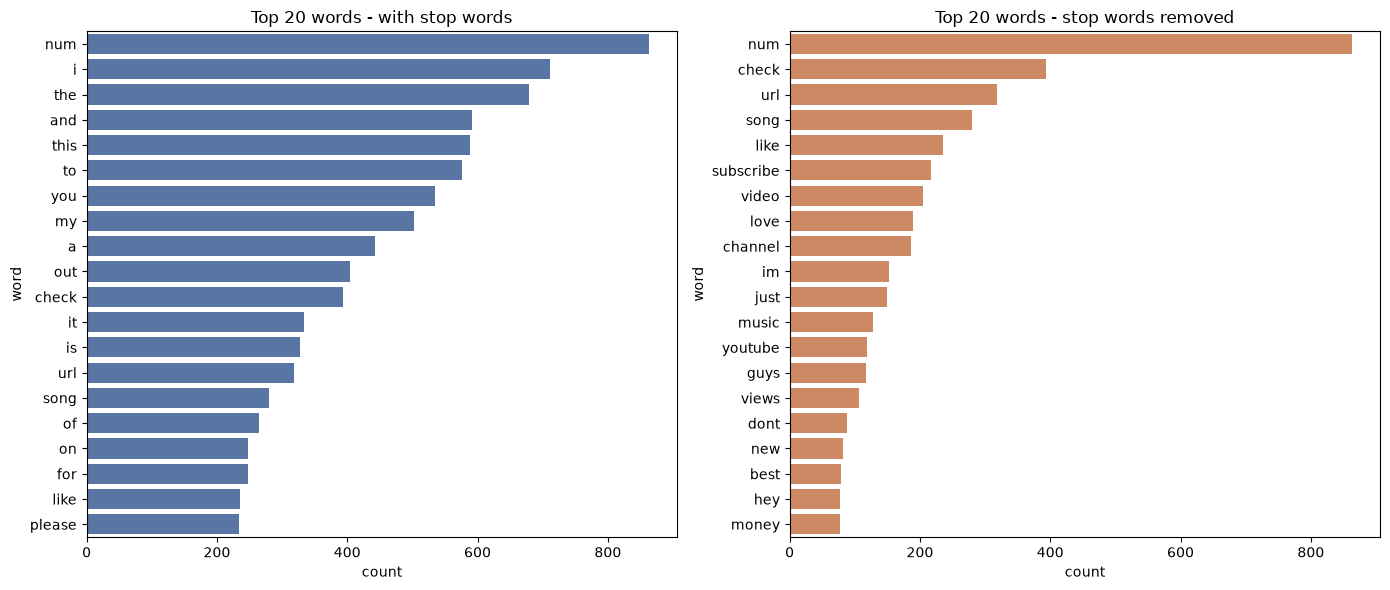

In [25]:
counter_all = Counter(all_tokens)
counter_nostop = Counter(t for t in all_tokens if t not in ENGLISH_STOP_WORDS)

top_all = pd.DataFrame(counter_all.most_common(20), columns=["word", "count"], index=range(1, 21))
top_nostop = pd.DataFrame(counter_nostop.most_common(20), columns=["word", "count"], index=range(1, 21))

display(pd.concat({"WITH stop words": top_all, "WITHOUT stop words": top_nostop}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top_all, x="count", y="word", color="#4C72B0", ax=axes[0])
axes[0].set_title("Top 20 words - with stop words")
sns.barplot(data=top_nostop, x="count", y="word", color="#DD8452", ax=axes[1])
axes[1].set_title("Top 20 words - stop words removed")
plt.tight_layout()
plt.savefig(FIG_DIR / "word_frequency.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparison (Spam VS Not Spam):

,records,avg_char_length,avg_word_count
LABEL,,,
Not Spam,913,51.08,9.26
Spam,840,145.61,22.25


Not Spam             Spam      
      word count       word count
0      num   346        num   517
1     song   214      check   381
2     love   139        url   313
3    views    87  subscribe   216
4     like    87    channel   186
5    video    85       like   149
6  billion    56         im   125
7     best    56      video   119
8     katy    54       guys   114
9     good    48       just   106

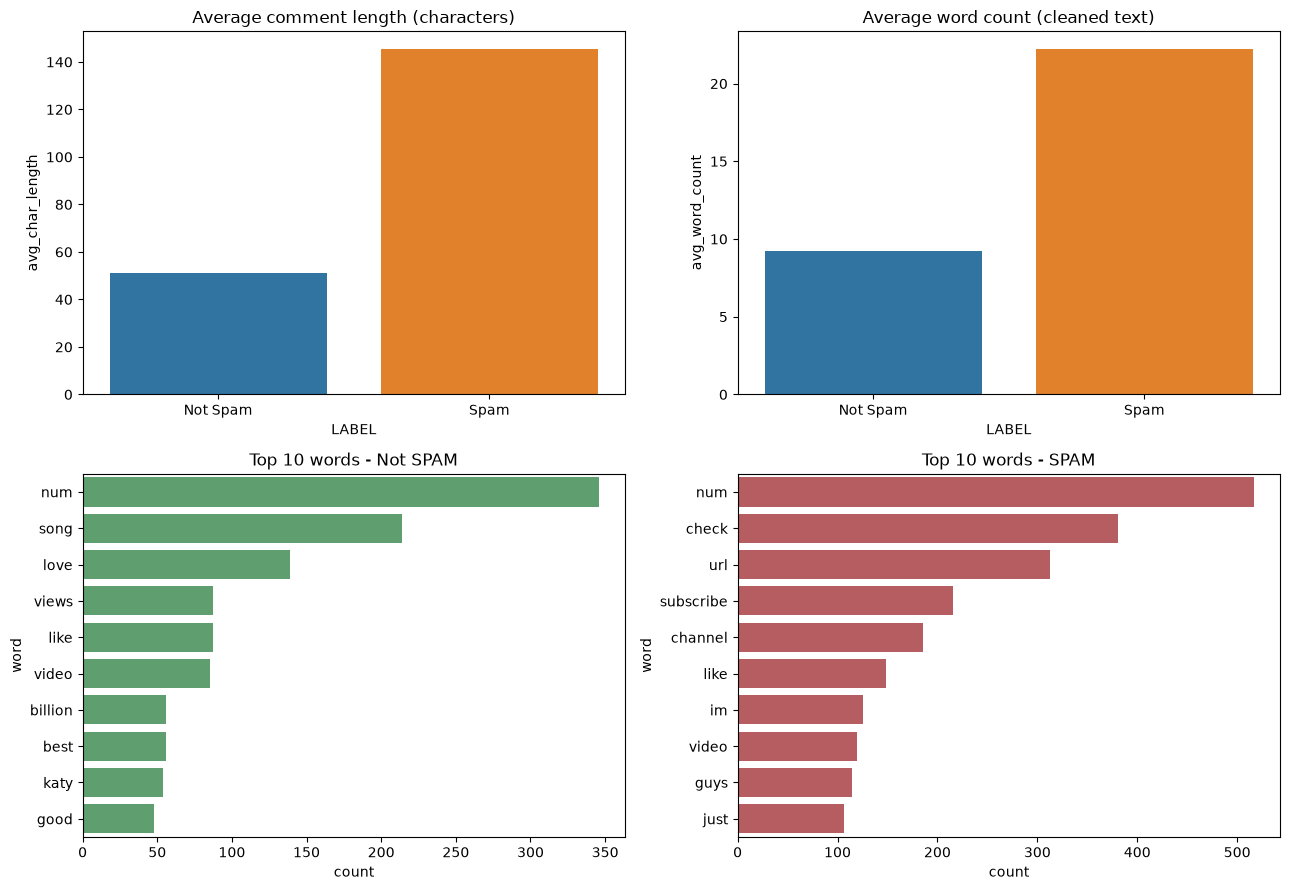

In [26]:
group_stats = (df.groupby("LABEL")
                 .agg(records=("CLASS", "size"),
                      avg_char_length=("char_count", "mean"),
                      avg_word_count=("token_count", "mean"))
                 .round(2))
display(group_stats)

def top_words(token_lists, n=10):
    c = Counter(t for toks in token_lists for t in toks if t not in ENGLISH_STOP_WORDS)
    return c.most_common(n)

top_notspam = top_words(df.loc[df["LABEL"] == "Not Spam", "tokens"])
top_spam = top_words(df.loc[df["LABEL"] == "Spam", "tokens"])
display(pd.concat({"Not Spam": pd.DataFrame(top_notspam, columns=["word", "count"]),
                   "Spam": pd.DataFrame(top_spam, columns=["word", "count"])}, axis=1))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.barplot(x=group_stats.index, y=group_stats["avg_char_length"], hue=group_stats.index, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Average comment length (characters)")
sns.barplot(x=group_stats.index, y=group_stats["avg_word_count"], hue=group_stats.index, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Average word count (cleaned text)")
for ax, data, title, col in [(axes[1, 0], top_notspam, "Top 10 words - Not SPAM", "#55A868"),
                             (axes[1, 1], top_spam, "Top 10 words - SPAM", "#C44E52")]:
    d = pd.DataFrame(data, columns=["word", "count"])
    sns.barplot(data=d, x="count", y="word", color=col, ax=ax)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG_DIR / "group_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# Insight

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1753 entries, 0 to 1752
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   COMMENT_ID         1753 non-null   str                
 1   AUTHOR             1753 non-null   str                
 2   DATE               1546 non-null   datetime64[us, UTC]
 3   CONTENT            1753 non-null   str                
 4   CLASS              1753 non-null   int64              
 5   VIDEO              1753 non-null   category           
 6   LABEL              1753 non-null   str                
 7   VIDEO_CODE         1753 non-null   int8               
 8   char_count         1753 non-null   int64              
 9   length_bin         1753 non-null   category           
 10  char_count_scaled  1753 non-null   float64            
 11  word_count         1753 non-null   int64              
 12  unique_word_count  1753 non-null   int64              
 13 

In [28]:
by_label = df.groupby("LABEL")
evidence = pd.DataFrame({
    "% comments containing a URL": by_label["url_count"].apply(lambda s: (s > 0).mean() * 100),
    "avg exclamation marks": by_label["exclamation_count"].mean(),
    "avg uppercase ratio": by_label["uppercase_ratio"].mean(),
    "avg digits per comment": by_label["digit_count"].mean(),
    "avg characters": by_label["char_count"].mean(),
}).round(3)
display(evidence.T)

print("Spam rate (%) per video:")
display((df.groupby("VIDEO", observed=True)["CLASS"].mean() * 100).round(1).to_frame("spam_%"))

LABEL,Not Spam,Spam
% comments containing a URL,0.876,22.619
avg exclamation marks,1.113,1.800
avg uppercase ratio,0.092,0.111
avg digits per comment,0.911,4.825
avg characters,51.082,145.613


Spam rate (%) per video:


,spam_%
VIDEO,
Eminem,51.4
KatyPerry,50.1
LMFAO,42.8
Psy,50.3
Shakira,44.0


| # | Observation (what you see) | Evidence (numbers/charts) | Interpretation (what it means) |
|---|---|---|---|
| 1 | Spam comments are much longer than real ones. | Average length for spam is 145.6 characters vs 51.1 characters for not spam. | Spammers paste promotional text or long urls. |
| 2 | URLs are a strong spam marker, but not the best. | 22.6% of spam comments contain a URL vs 0.88% of not spam comments. | A link almost always means spam. But about 77% of spam don't have a URL. |
| 3 | Spam comments contain more digits than not spam comments. | 4.8 digits per spam comment vs 0.9 for not spam. | Spam sometimes includes numbers such as “100% free”. |
| 4 | Spam uses exclamation marks slightly than not spam. | 1.800 avg for spam vs 1.113 for not spam. | Spam comments are more likely to use exclamation marks to attrach people. |
| 5 | Spam rates are similar across different video creators. | Spam percentage is about 50-51% for Eminem, Psy and KatyPerry, while 42.8% for LMFAO and 44.0% for Shakira. | Not one video is being chosen as a special target for Spamming. |

In [29]:
df.to_csv(OUT_DIR / "cleaned_data.csv", index=False)
print("Saved:", (OUT_DIR / "cleaned_data.csv").resolve(), "| shape:", df.drop(columns=["tokens"]).shape)

Saved: /home/jovyan/work/output/cleaned_data.csv | shape: (1753, 20)


# Supervised Text Classification:

In [30]:
X = df["cleaned_text"]
y = df["CLASS"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED) # stratified split to keep them equal

print("Train:", len(X_train), "| Test:", len(X_test))
print("Spam share  train: %.1f%%  test: %.1f%%" % (y_train.mean() * 100, y_test.mean() * 100))

Train: 1402 | Test: 351
Spam share  train: 47.9%  test: 47.9%


In [31]:
def make_vectorizer(ngram_range=(1, 1)):
    return TfidfVectorizer(min_df=2, ngram_range=ngram_range, sublinear_tf=True) #Convert text to numerical features

experiments = {
    "Logistic Regression (unigrams)":   (make_vectorizer((1, 1)), LogisticRegression(max_iter=1000, random_state=SEED)),
    "Multinomial NB (unigrams)":        (make_vectorizer((1, 1)), MultinomialNB()),
    "Logistic Regression (uni+bigrams)": (make_vectorizer((1, 2)), LogisticRegression(max_iter=1000, random_state=SEED)),
}

rows, predictions, fitted = [], {}, {}
for name, (vec, clf) in experiments.items():
    Xtr = vec.fit_transform(X_train)          # fit on TRAIN only
    Xte = vec.transform(X_test)
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xte)
    predictions[name], fitted[name] = pred, (vec, clf)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "precision (spam)": precision_score(y_test, pred),
                 "recall (spam)": recall_score(y_test, pred),
                 "f1 (spam)": f1_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("model").round(4)
display(results)

PRIMARY = "Logistic Regression (unigrams)"
print("\nClassification report - PRIMARY model:", PRIMARY)
print(classification_report(y_test, predictions[PRIMARY], target_names=["not spam", "spam"], digits=3))

,accuracy,precision (spam),recall (spam),f1 (spam)
model,,,,
Logistic Regression (unigrams),0.9459,0.9745,0.9107,0.9415
Multinomial NB (unigrams),0.9259,0.9329,0.9107,0.9217
Logistic Regression (uni+bigrams),0.9402,0.9804,0.8929,0.9346



Classification report - PRIMARY model: Logistic Regression (unigrams)
              precision    recall  f1-score   support

    not spam      0.923     0.978     0.950       183
        spam      0.975     0.911     0.942       168

    accuracy                          0.946       351
   macro avg      0.949     0.944     0.946       351
weighted avg      0.947     0.946     0.946       351



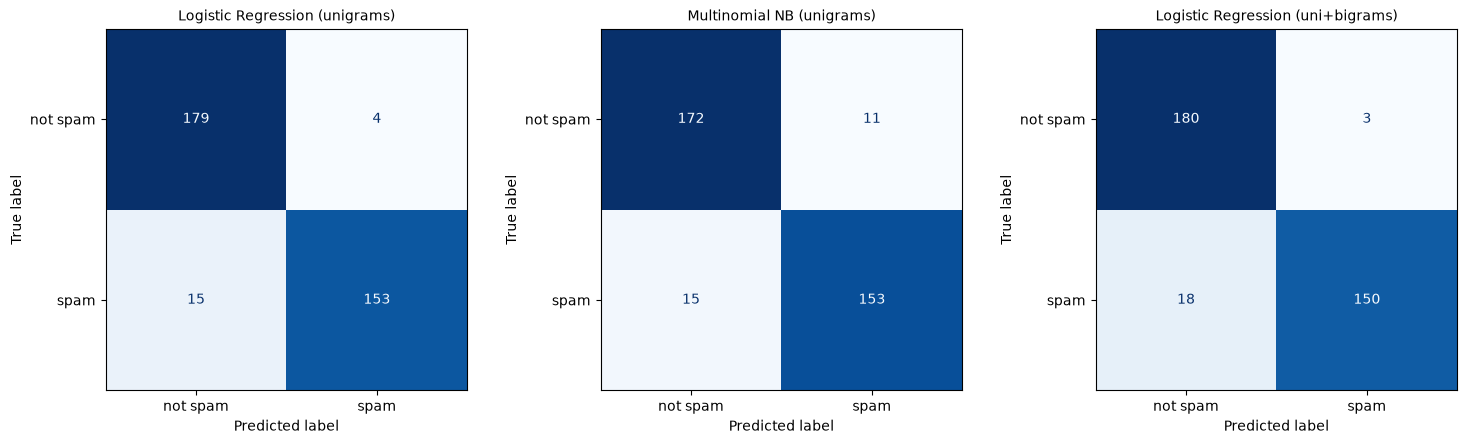

PRIMARY model -> TN=179 (not spam correctly kept) | FP=4 (not spam wrongly flagged as spam) | FN=15 (spam missed) | TP=153 (spam caught)


In [32]:
fig, axes = plt.subplots(1, len(predictions), figsize=(5 * len(predictions), 4.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not spam", "spam"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

cm = confusion_matrix(y_test, predictions[PRIMARY])
tn, fp, fn, tp = cm.ravel()
print(f"PRIMARY model -> TN={tn} (not spam correctly kept) | FP={fp} (not spam wrongly flagged as spam) | FN={fn} (spam missed) | TP={tp} (spam caught)")

In [33]:
# Which words push a comment towards spam / not spam? (Logistic Regression coefficients)
vec, clf = fitted[PRIMARY]
feature_names = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])
top_notspam_feats = list(feature_names[order[:12]])
top_spam_feats = list(feature_names[order[::-1][:12]])
display(pd.DataFrame({"most 'not spam' words": top_notspam_feats, "most 'spam' words": top_spam_feats}))

# 5-fold cross-validation of the primary model for a more stable estimate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pipe = make_pipeline(make_vectorizer((1, 1)), LogisticRegression(max_iter=1000, random_state=SEED))
cv_f1 = cross_val_score(pipe, X, y, cv=cv, scoring="f1")
cv_acc = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
print("5-fold CV accuracy: %.3f +/- %.3f" % (cv_acc.mean(), cv_acc.std()))
print("5-fold CV F1 (spam): %.3f +/- %.3f" % (cv_f1.mean(), cv_f1.std()))

,most 'not spam' words,most 'spam' words
0,song,url
1,views,subscribe
2,love,out
3,is,check
4,billion,please
5,shakira,channel
6,best,my
7,good,comment
8,came,if
9,years,for


5-fold CV accuracy: 0.938 +/- 0.016
5-fold CV F1 (spam): 0.933 +/- 0.018


In [34]:
# Save model_metrics.txt
p = predictions[PRIMARY]
lines = [
    "SUPERVISED TEXT CLASSIFICATION - YouTube Spam Collection",
    "=" * 60,
    f"Records used : {len(df)}  (train={len(X_train)}, test={len(X_test)}; stratified 80/20 split, random_state={SEED})",
    "Target       : CLASS (1 = spam, 0 = not spam)",
    "Features     : TF-IDF on cleaned_text (min_df=2, sublinear_tf=True)",
    "",
    f"PRIMARY MODEL: {PRIMARY}",
    f"Accuracy  : {accuracy_score(y_test, p):.4f}",
    f"Precision : {precision_score(y_test, p):.4f}  (spam class)",
    f"Recall    : {recall_score(y_test, p):.4f}  (spam class)",
    f"F1-score  : {f1_score(y_test, p):.4f}  (spam class)",
    "",
    "Confusion matrix (rows = true, columns = predicted; order: not spam, spam):",
    str(confusion_matrix(y_test, p)),
    f"TN={tn}, FP={fp}, FN={fn}, TP={tp}",
    "",
    "Classification report:",
    classification_report(y_test, p, target_names=["not spam", "spam"], digits=3),
    "Model comparison (bonus: two classifiers + n-gram extension):",
    results.to_string(),
    "",
    f"5-fold CV accuracy: {cv_acc.mean():.3f} +/- {cv_acc.std():.3f}",
    f"5-fold CV F1 (spam): {cv_f1.mean():.3f} +/- {cv_f1.std():.3f}",
    "",
    "Words pushing towards SPAM : " + ", ".join(top_spam_feats),
    "Words pushing towards NOT SPAM  : " + ", ".join(top_notspam_feats),
    "",
    "Interpretation:",
    f"The primary model classifies {accuracy_score(y_test, p):.1%} of test comments correctly. "
    f"It catches {recall_score(y_test, p):.1%} of the spam (recall) and {precision_score(y_test, p):.1%} of the comments it flags are really spam (precision).",
    "Limitations: small dataset collected from only five music videos, so the model may not generalise to other channels or newer spam styles; "
    "TF-IDF is a bag of words and ignores word order and context; a random split places comments from the same videos in train and test, "
    "which can make the scores optimistic; cleaning drops emojis and non-Latin text.",
]
(OUT_DIR / "model_metrics.txt").write_text("\n".join(lines), encoding="utf-8")
print("Saved:", (OUT_DIR / "model_metrics.txt").resolve())

Saved: /home/jovyan/work/output/model_metrics.txt


# Interpretation & Limitation:

Logistic Regression with unigram TF-IDF performed best, with an accuracy of 94.6% and an F1-score of 0.942. 

Limitation: the dataset is small and comes from only five music videos, so the model may not generalise to other channels or newer spam styles

# K-Means clustering:

In [35]:
tfidf_km = TfidfVectorizer(min_df=2, stop_words="english", sublinear_tf=True)
X_tfidf = tfidf_km.fit_transform(df["cleaned_text"])

n_comp = min(100, X_tfidf.shape[1] - 1)
svd = TruncatedSVD(n_components=n_comp, random_state=SEED)
X_svd = Normalizer(copy=False).fit_transform(svd.fit_transform(X_tfidf))

print("TF-IDF matrix:", X_tfidf.shape, "-> SVD:", X_svd.shape)

TF-IDF matrix: (1753, 1163) -> SVD: (1753, 100)


,inertia,silhouette
k,,
2,1548.7107,0.0545
3,1492.3710,0.0668
4,1442.0432,0.0763
5,1396.1168,0.0859
6,1364.8630,0.0906
7,1323.5923,0.1006
8,1303.2281,0.1047


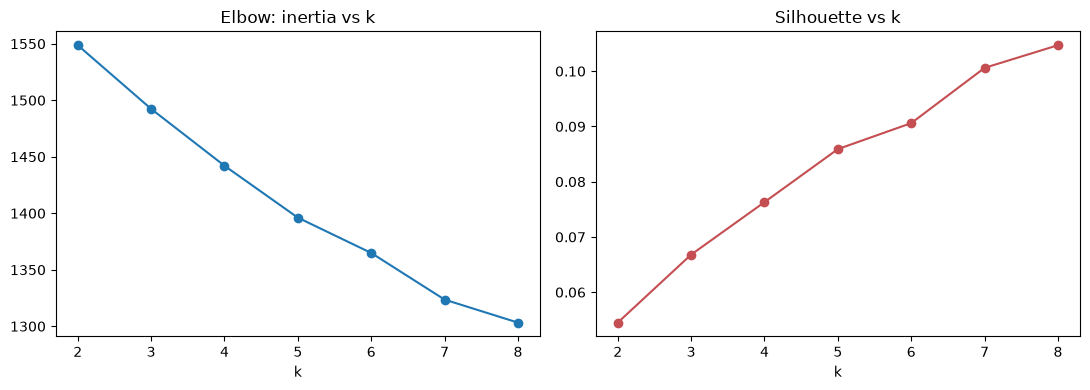

k with the highest silhouette: 8 | k used: 8


In [36]:
# Testing different k values - silhouette score (higher = better separated) and inertia (elbow)
rows = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_svd) #fitting with SVD
    rows.append({"k": k, "inertia": km_k.inertia_, "silhouette": silhouette_score(X_svd, km_k.labels_)})
k_results = pd.DataFrame(rows).set_index("k").round(4)
display(k_results)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_results.index, k_results["inertia"], marker="o"); axes[0].set_title("Elbow: inertia vs k"); axes[0].set_xlabel("k")
axes[1].plot(k_results.index, k_results["silhouette"], marker="o", color="#C44E52"); axes[1].set_title("Silhouette vs k"); axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig(FIG_DIR / "kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

K_FINAL = int(k_results["silhouette"].idxmax())
print("k with the highest silhouette:", K_FINAL, "| k used:", K_FINAL)

In [37]:
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(X_svd)
df["cluster"] = km.labels_
sil = silhouette_score(X_svd, km.labels_)

sizes = df["cluster"].value_counts().sort_index()
print(f"k = {K_FINAL} | silhouette score = {sil:.4f}")
display(sizes.to_frame("records"))

# Top words in clusters
terms = np.array(tfidf_km.get_feature_names_out())
centroids = svd.inverse_transform(km.cluster_centers_)
top_terms = {c: list(terms[np.argsort(centroids[c])[::-1][:10]]) for c in range(K_FINAL)}
for c, t in top_terms.items():
    print(f"Cluster {c} ({sizes[c]} records): {', '.join(t)}")

k = 8 | silhouette score = 0.1047


,records
cluster,
0,717
1,170
2,132
3,139
4,118
5,60
6,246
7,171


Cluster 0 (717 records): like, music, just, good, im, check, video, eminem, channel, best
Cluster 1 (170 records): check, youtube, video, channel, playlist, new, music, hey, thanks, eminem
Cluster 2 (132 records): subscribe, channel, like, videos, ill, guys, num, hey, check, thanks
Cluster 3 (139 records): song, best, good, like, old, just, world, nice, beautiful, awesome
Cluster 4 (118 records): love, song, shakira, lie, way, eminem, num, songs, nice, old
Cluster 5 (60 records): katy, perry, love, num, roar, songs, official, like, great, url
Cluster 6 (246 records): num, views, billion, watching, like, video, years, million, people, subscribers
Cluster 7 (171 records): url, num, money, check, make, visit, online, today, website, month


Clusters vs true labels (counts):


LABEL,Not Spam,Spam
cluster,,
0,452,265
1,18,152
2,0,132
3,121,18
4,106,12
5,47,13
6,169,77
7,0,171


Clusters vs true labels (% of cluster):


LABEL,Not Spam,Spam
cluster,,
0,63.0,37.0
1,10.6,89.4
2,0.0,100.0
3,87.1,12.9
4,89.8,10.2
5,78.3,21.7
6,68.7,31.3
7,0.0,100.0


Clusters vs videos (counts):


VIDEO,Eminem,KatyPerry,LMFAO,Psy,Shakira
cluster,,,,,
0,186,116,157,119,139
1,54,19,42,38,17
2,24,16,40,28,24
3,34,21,30,13,41
4,36,17,18,3,44
5,0,59,0,0,1
6,45,29,48,90,34
7,24,68,4,57,18


Adjusted Rand Index between clusters and spam/not spam labels: 0.082  (0 = unrelated, 1 = identical grouping)


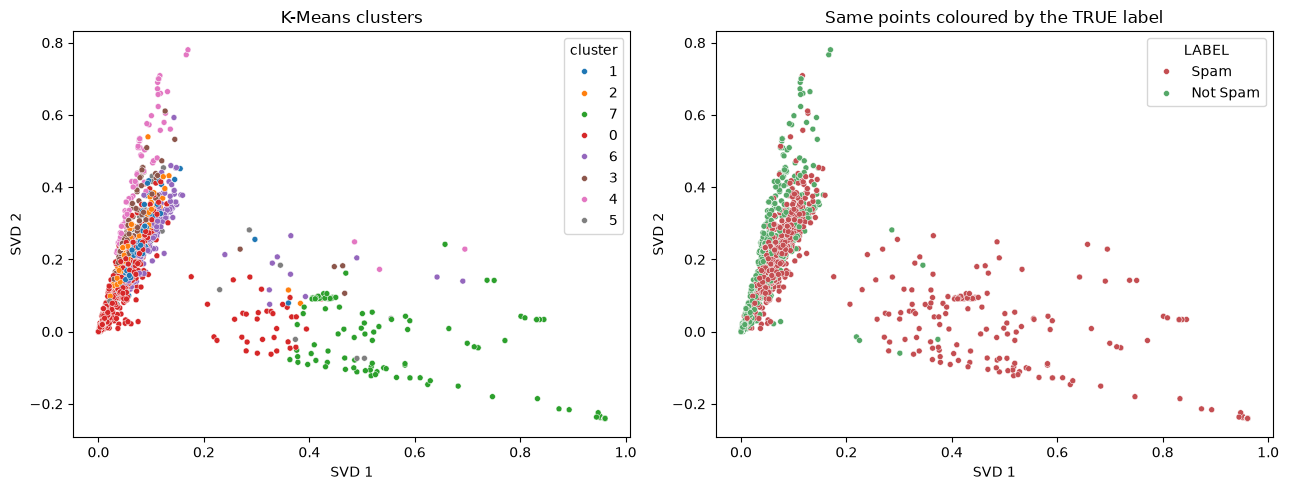

In [38]:
label_by_cluster = pd.crosstab(df["cluster"], df["LABEL"])
label_pct = (pd.crosstab(df["cluster"], df["LABEL"], normalize="index") * 100).round(1)
video_by_cluster = pd.crosstab(df["cluster"], df["VIDEO"])

print("Clusters vs true labels (counts):");  display(label_by_cluster)
print("Clusters vs true labels (% of cluster):");  display(label_pct)
print("Clusters vs videos (counts):");  display(video_by_cluster)

ari = adjusted_rand_score(df["CLASS"], df["cluster"])
print(f"Adjusted Rand Index between clusters and spam/not spam labels: {ari:.3f}  (0 = unrelated, 1 = identical grouping)")

# 2-D picture of the clusters (first two SVD dimensions)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(x=X_svd[:, 0], y=X_svd[:, 1], hue=df["cluster"].astype(str), palette="tab10", s=18, ax=axes[0])
axes[0].set_title("K-Means clusters"); axes[0].set_xlabel("SVD 1"); axes[0].set_ylabel("SVD 2")
sns.scatterplot(x=X_svd[:, 0], y=X_svd[:, 1], hue=df["LABEL"], palette={"Not Spam": "#55A868", "Spam": "#C44E52"}, s=18, ax=axes[1])
axes[1].set_title("Same points coloured by the TRUE label"); axes[1].set_xlabel("SVD 1"); axes[1].set_ylabel("SVD 2")
plt.tight_layout()
plt.savefig(FIG_DIR / "cluster_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [39]:
def describe_cluster(spam_pct):
    if spam_pct >= 70: return "mostly spam"
    if spam_pct <= 30: return "mostly legitimate (not spam)"
    return "a mix of spam and not spam"

lines = [
    "K-MEANS CLUSTERING SUMMARY - YouTube Spam Collection",
    "=" * 60,
    f"Records clustered : {len(df)}",
    "Representation    : TF-IDF (stop words removed, min_df=2) -> TruncatedSVD "
    f"({n_comp} components) -> L2 normalisation",
    f"k tried           : 2..8 | k used: {K_FINAL} (highest silhouette unless changed manually)",
    f"Silhouette score  : {sil:.4f}  (range -1..1; values near 0 mean overlapping clusters)",
    "",
    "Silhouette / inertia per k:",
    k_results.to_string(),
    "",
    "Cluster sizes and interpretation:",
]
for c in range(K_FINAL):
    spam_pct = label_pct.loc[c, "spam"] if "spam" in label_pct.columns else 0.0
    main_video = video_by_cluster.loc[c].idxmax()
    lines.append(f"- Cluster {c}: {sizes[c]} records | {spam_pct:.1f}% spam -> {describe_cluster(spam_pct)} | "
                 f"most common video: {main_video}")
    lines.append(f"    top terms: {', '.join(top_terms[c])}")
lines += [
    "",
    "Clusters vs true labels (counts):",
    label_by_cluster.to_string(),
    "",
    f"Adjusted Rand Index vs spam/not spam labels: {ari:.3f}",
    "",
    "Comparison with the known labels:",
    "K-Means is unsupervised, so cluster ids are arbitrary and do not have to equal the class ids. "
    "Clusters are compared with the labels only afterwards, by looking at the share of spam inside each cluster. "
    "A cluster that is mostly spam (or mostly not spam) means the words alone separate part of the classes; "
    "mixed clusters mean the grouping follows other themes (e.g. praise, a specific artist, short reactions) instead of spam vs not spam.",
]
(OUT_DIR / "cluster_summary.txt").write_text("\n".join(lines), encoding="utf-8")
print("Saved:", (OUT_DIR / "cluster_summary.txt").resolve())

# Re-save the cleaned data with the cluster column included
df.drop(columns=["tokens"]).to_csv(OUT_DIR / "cleaned_data.csv", index=False)
print("Re-saved cleaned_data.csv with the cluster column.")

Saved: /home/jovyan/work/output/cluster_summary.txt
Re-saved cleaned_data.csv with the cluster column.


In [40]:
for name in ["cleaned_data.csv", "model_metrics.txt", "cluster_summary.txt"]:
    f = OUT_DIR / name
    print(f"{name:22s} exists={f.exists()}  size={f.stat().st_size if f.exists() else 0:,} bytes")

figs = sorted(FIG_DIR.glob("*.png"))
print(f"\nFigures saved ({len(figs)}):")
for f in figs:
    print("  -", f.name)

cleaned_data.csv       exists=True  size=628,342 bytes
model_metrics.txt      exists=True  size=2,293 bytes
cluster_summary.txt    exists=True  size=2,949 bytes

Figures saved (7):
  - cluster_plot.png
  - confusion_matrix.png
  - correlation_heatmap.png
  - group_comparison.png
  - kmeans_k_selection.png
  - sampling_comparison.png
  - word_frequency.png
